# Nelson Submission - AAA Bias Free LA Jobs

#### First, thank you to the City of Los Angeles and Kaggle for hosting this interesting competition.  I'm already using these tools at work to improve our documents.  

### Challenge:

The City of Los Angeles requested tools to check Job Bulletins for biased words and a CSV file containing Job Bulletin data plus Career Paths in DAG format.  A DAG is a special data structure that looks like a family-tree.  A Career Path DAG contains the path a City employee would take for promotions.

### Solution:

I offer this two-part strategy:

**Part 1** a prototype app that finds bias words using a Natural Language Processing (NLP) 

**Part 2** proof of concept scripts that create a CSV file with text gathered from the Job Bulletins and Career Paths.  I included Career Path data in DAG format and added a NEXT_PROMOTION field.  



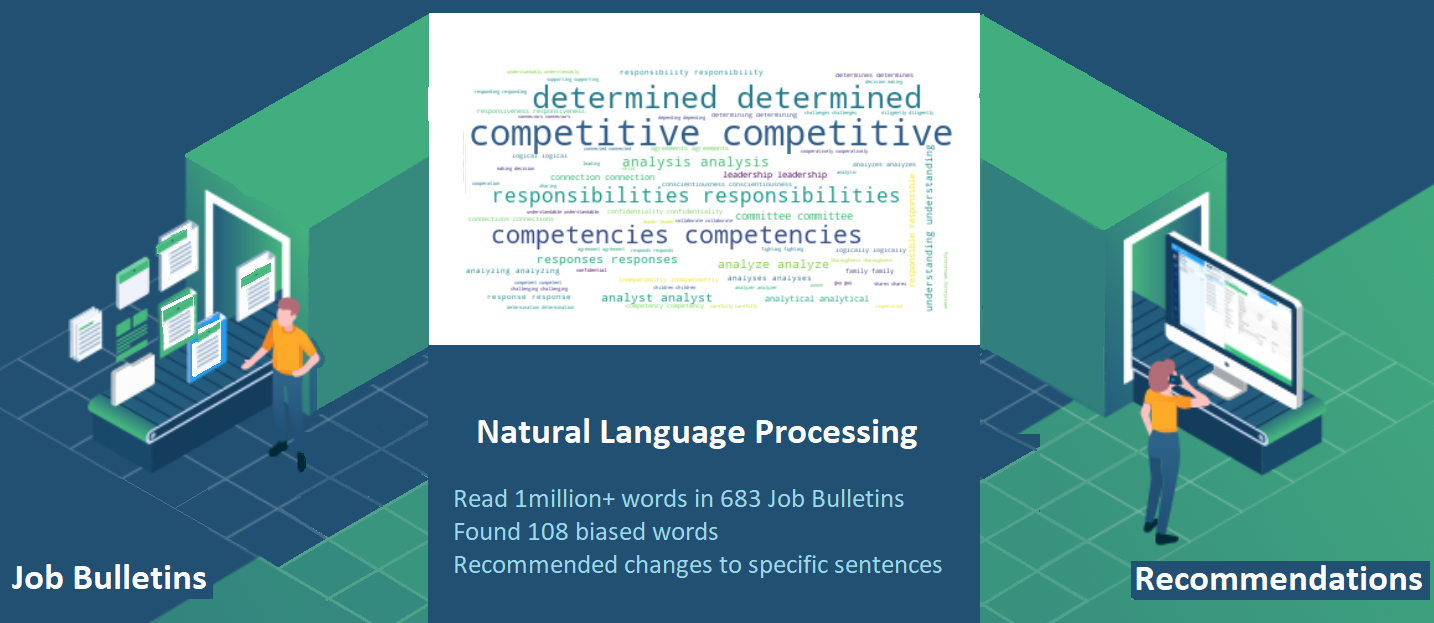

In [1]:
from IPython.display import Image
Image("../input/jobbulletinresults/machine.png")

#### Part 1:  Finding Bias Words using Natural Language Processing (NLP)

RESULTS:  The City of Los Angeles has taken care to write Job Bulletins that are free from bias.  Only 2% of the words in Job Bulletins may be biased.  Only 12% of the time biased words are used.

Having led projects in 27 countries (so far), I study how language affects team productivity.  Teams thrive in collaborative environments with clear goals.  When staffing teams, I write job descriptions using short, simple words so that all candidates can read them, even "non-native" English speakers who didn't learn English as their first language.  

Additionally, I realize that some team members respond negatively to gender-bias words.  Some job candidates told me that they don't like a "competitive" work environment.  Steering clear of bias can be difficult.  Fortunately, Gaucher, Friesen, and Kay researched gender bias in job advertisements and made a list of gender-coded words. They published this list in "Evidence That Gendered Wording in Job Advertisements Exists and Sustains Gender Inequality" in the Journal of Personality and Social Psychology, July 2011, Vol 101(1), p109-28.  I used this list to evaluate the City of Los Angeles Job Bulletins.  

Text analysis can be fast and accurate because the original Job Bulletins are processed directly.  There is no "middle-man" converting them to a database first.  I was able to go beyond proof of concept and conduct an automated review looking for biased words that might discourage job applicants.  The City of Los Angeles scored very well.  Check out this kernel:

[BiasAnalyzer kernel](https://www.kaggle.com/nelsondata/BiasAnalyzer)

BiasAnalyzer is modular so you can plug-in other tools from this competition or from other sources.  Here are two modules that I included:

[WordCounts kernel](https://www.kaggle.com/nelsondata/wordcounts)

[Big Huge Thesaurus API kernel](https://www.kaggle.com/nelsondata/bighugethesaurusapi-jobads)

The following diagram shows how it works:

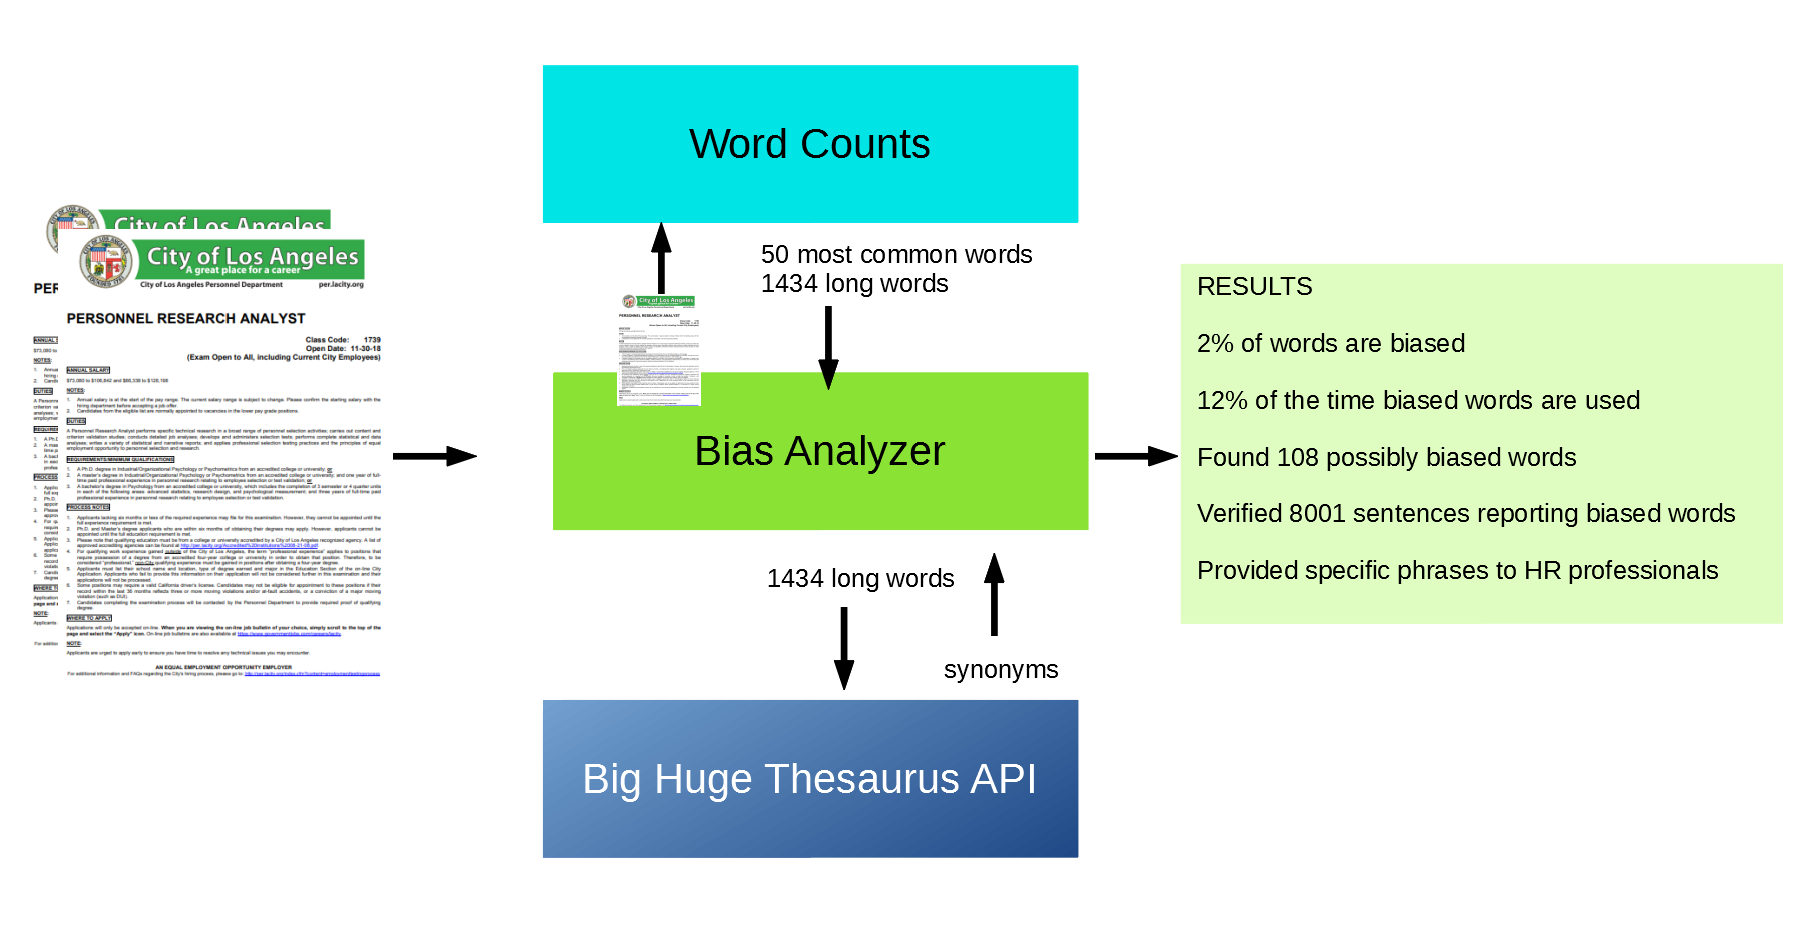

In [2]:
from IPython.display import Image
Image("../input/jobbulletinresults/Bias.png")

### Part 2:  Gathering data from Job Bulletins and Career Paths

First, I used the [Text2CSV kernel](https://www.kaggle.com/nelsondata/text2csv) to gather data from Job Bulletins.  Then, I used [Chart2DAG](https://www.kaggle.com/nelsondata/chart2dag) to generate DAGs.  I created a CSV file containing the data requested in the competition guidelines plus data from the Career Paths.

#### Text2CSV
[Text2CSV kernel](https://www.kaggle.com/nelsondata/text2csv) gathers data from Job Bulletins and creates JobBulletin.csv

#### Chart2DAG
[Chart2DAG](https://www.kaggle.com/nelsondata/chart2dag) reads the Career Path charts and generate DAGs.  Updates JobBulletins.csv.  I added the NEXT_PROMOTION field so that you can quickly see the next step in your career path. 



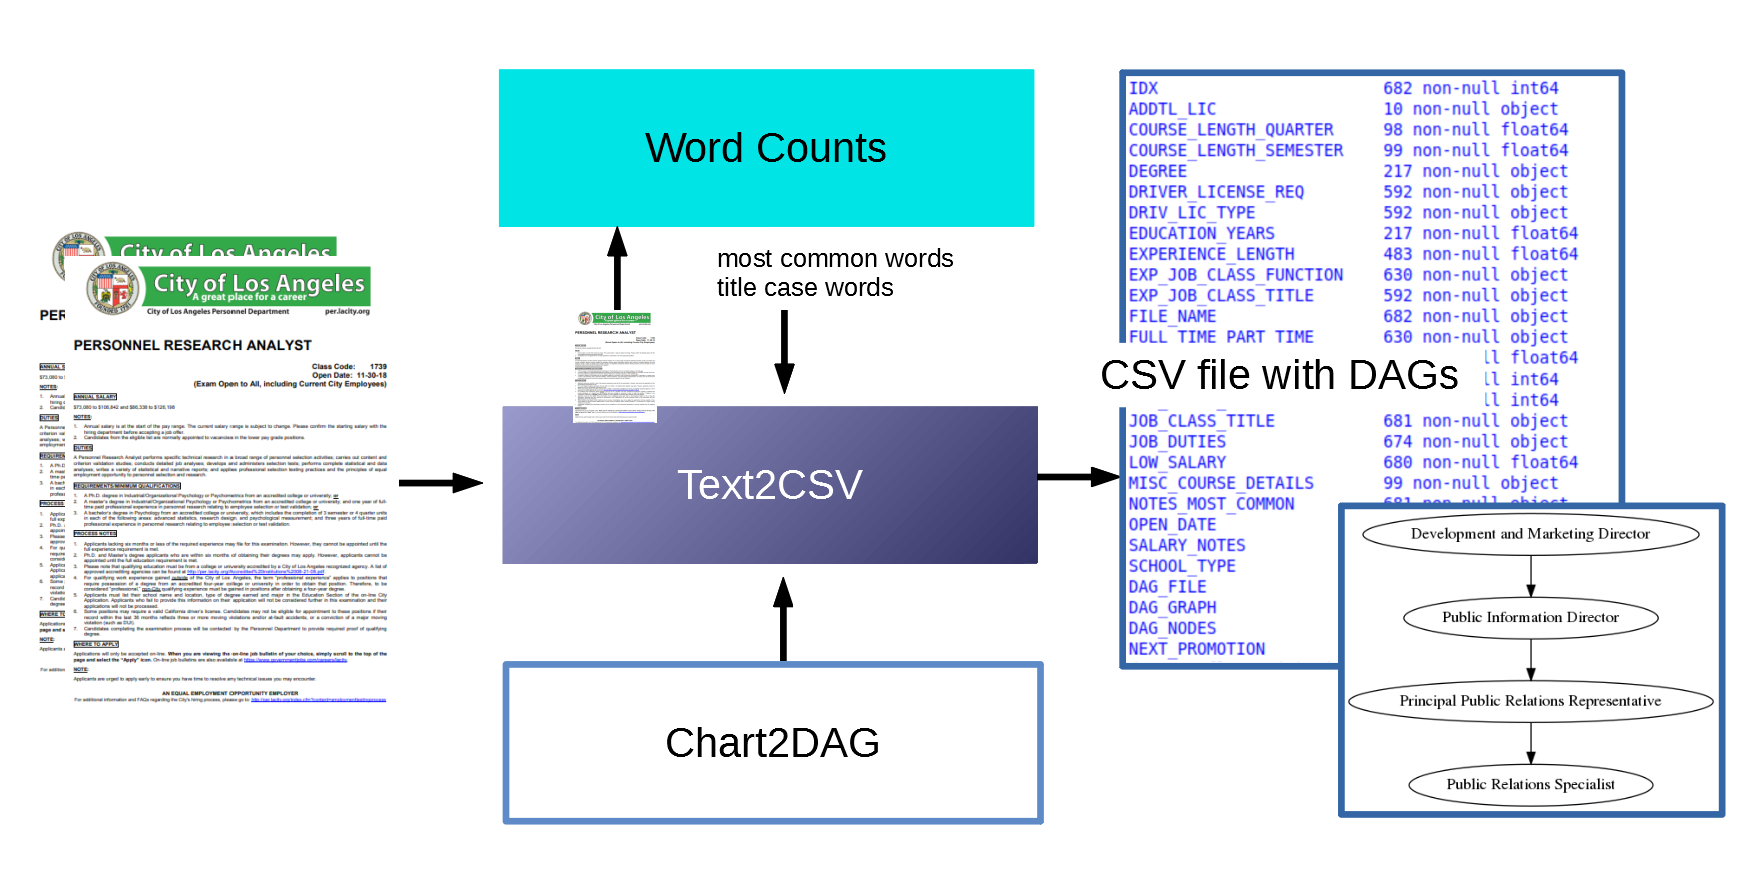

In [3]:
from IPython.display import Image
Image("../input/jobbulletinresults/Text2CSV.png")


#### List of Kernels

AAA-BiasFree-LAJob - https://www.kaggle.com/nelsondata/aaa-biasfree-lajobs (this kernel)

BiasAnalyzer kernel - https://www.kaggle.com/nelsondata/BiasAnalyzer

BigHugeThesaurusAPI-JobAds - https://www.kaggle.com/nelsondata/bighugethesaurusapi-jobads

Chart2DAG - https://www.kaggle.com/nelsondata/chart2dag

Text2CSV - https://www.kaggle.com/nelsondata/text2csv

WordCounts - https://www.kaggle.com/nelsondata/wordcounts

#### List of Datasets

CareerPathData - https://www.kaggle.com/nelsondata/careerpathdata

JobBulletinData - https://www.kaggle.com/nelsondata/jobbulletindata

JobBulletinResults -  https://www.kaggle.com/nelsondata/jobbulletinresults

In [4]:
'''
Script:  Stats.py
Purpose: Provide new insights about Job Bulletins and Career Paths
'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# dnlp:  get statistics from JBR_NLP.py
dnlp = pd.read_csv('../input/jobbulletinresults/JBR_Output/fileStats.csv')
pd.options.display.max_columns=len(dnlp)

# dbias and dbw:  get statistics from biasVerifier.py
dbias = pd.read_csv('../input/jobbulletinresults/JBR_Output/BiasedWords.csv')
dbw = dbias[['FILE_NAME','WORD']]


In [5]:
# dbw2:  dataframe containing filename and the number of biased words found in it
dbw2 = pd.DataFrame({'TOT_BIAS_WORDS':dbw.groupby(['FILE_NAME'])['WORD'].count()}).reset_index()

# dstats: dataframe with statistics from word analysis in JBR_NLP and bias analysis in biasVerifier
dstats = pd.merge(dnlp,dbw2, how="left", on='FILE_NAME')
dstats["TOT_BIAS_WORDS"] = dstats["TOT_BIAS_WORDS"].fillna(0.0)
dstats["TOT_BIAS_WORDS"] = dstats["TOT_BIAS_WORDS"].astype('int64')

In [6]:
# djbstats:  merge statistics with Job Bulletin data
jb = pd.read_csv("../input/jobbulletinresults/JBR_Output/JobBulletin.csv")
djbstats = pd.merge(jb,dstats,how="left",on='FILE_NAME')
# df and df2: slice the dataframe to gather only numeric and categories useful for analysis
df = djbstats[['DRIVER_LICENSE_REQ', 'DRIV_LIC_TYPE', 'EDUCATION_YEARS','EXPERIENCE_LENGTH', 'FULL_TIME_PART_TIME', 'HIGH_SALARY', 'LOW_SALARY','SCHOOL_TYPE', 'TOT_DIF_WORDS', 'TOT_LONG_WORDS','TOT_WORDS', 'TOT_BIAS_WORDS']]
df = df.fillna(0)
df2 = pd.get_dummies(df)

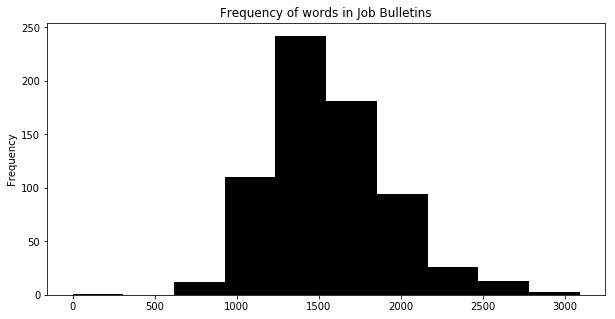


Longest Job Bulletin: 
3091  words in  JobBulletins/UNDERGROUND DISTRIBUTION CONSTRUCTION MECHANIC 3812 101918.txt

Shortest Job Bulletin:
0  words in  JobBulletins/POLICE COMMANDER 2251 092917.txt

Average Job Bulletin length:
1556  words


In [7]:
# CHARTS and REPORTS

dnlp['TOT_WORDS'].plot(figsize=(10,5), kind='hist', color='black', title='Frequency of words in Job Bulletins')
plt.show()    

print("\nLongest Job Bulletin: ")
longest = dnlp['TOT_WORDS'].max()
longs = dnlp['FILE_NAME'][dnlp['TOT_WORDS'] == longest]
for long in longs: print(longest, " words in ", long)

print("\nShortest Job Bulletin:")
shortest = dnlp['TOT_WORDS'].min()
shorts = dnlp['FILE_NAME'][dnlp['TOT_WORDS'] == shortest]
for short in shorts: print(shortest, " words in ", short)

print("\nAverage Job Bulletin length:")
avgJB = dnlp['TOT_WORDS'].mean()
print(int(round(avgJB,0)), " words")

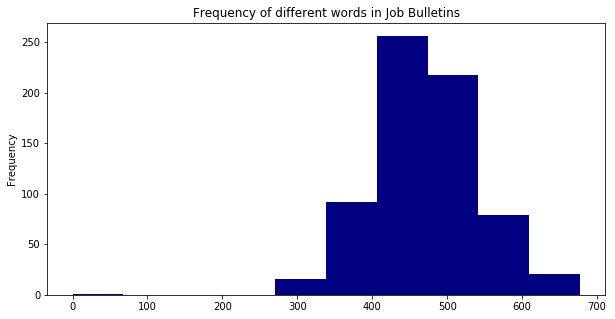


Job Bulletin with most different words: 
677  words in  JobBulletins/PROGRAMMER ANALYST 1431 092217 (3).txt
677  words in  JobBulletins/SYSTEMS PROGRAMMER 1455 091616 REV 100416.txt

Job Bulletin with the least number of different words:
0  words in  JobBulletins/POLICE COMMANDER 2251 092917.txt

Average Job Bulletin length based on different words:
471  words


In [8]:
dnlp['TOT_DIF_WORDS'].plot(figsize=(10,5), kind='hist', color='navy', title='Frequency of different words in Job Bulletins')
plt.show()    
print("\nJob Bulletin with most different words: ")
longest = dnlp['TOT_DIF_WORDS'].max()
longs = dnlp['FILE_NAME'][dnlp['TOT_DIF_WORDS'] == longest]
for long in longs: print(longest, " words in ", long)

print("\nJob Bulletin with the least number of different words:")
shortest = dnlp['TOT_DIF_WORDS'].min()
shorts = dnlp['FILE_NAME'][dnlp['TOT_DIF_WORDS'] == shortest]
for short in shorts: print(shortest, " words in ", short)

print("\nAverage Job Bulletin length based on different words:")
avgJB = dnlp['TOT_DIF_WORDS'].mean()
print(int(round(avgJB,0)), " words")

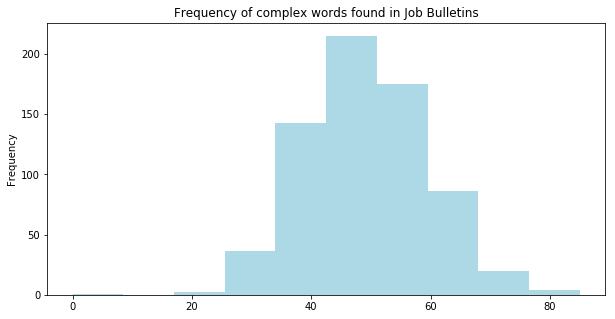


Job Bulletin with the most complex words: 
85  words in  JobBulletins/SENIOR REAL ESTATE OFFICER 1961 0413018 (2).txt

Job Bulletin with the least number of complex words:
0  words in  JobBulletins/POLICE COMMANDER 2251 092917.txt

Average Job Bulletin complexity:
49  words


In [9]:
dnlp['TOT_LONG_WORDS'].plot(figsize=(10,5), kind='hist', color='lightblue', title='Frequency of complex words found in Job Bulletins')
plt.show()    
print("\nJob Bulletin with the most complex words: ")
longest = dnlp['TOT_LONG_WORDS'].max()
longs = dnlp['FILE_NAME'][dnlp['TOT_LONG_WORDS'] == longest]
for long in longs: print(longest, " words in ", long)

print("\nJob Bulletin with the least number of complex words:")
shortest = dnlp['TOT_LONG_WORDS'].min()
shorts = dnlp['FILE_NAME'][dnlp['TOT_LONG_WORDS'] == shortest]
for short in shorts: print(shortest, " words in ", short)

print("\nAverage Job Bulletin complexity:")
avgJB = dnlp['TOT_LONG_WORDS'].mean()
print(int(round(avgJB,0)), " words")

In [10]:
print("Job Bulletins ranked from longest to shortest:\n")
dtot = dnlp[['FILE_NAME', 'TOT_WORDS']]
print(dtot.sort_values('TOT_WORDS', ascending=False))

Job Bulletins ranked from longest to shortest:

                                             FILE_NAME  TOT_WORDS
635  JobBulletins/UNDERGROUND DISTRIBUTION CONSTRUC...       3091
163    JobBulletins/DATABASE ARCHITECT 1470 083118.txt       2879
325  JobBulletins/ELECTRIC DISTRIBUTION MECHANIC 38...       2871
480  JobBulletins/EQUIPMENT OPERATOR 3525 041417 RE...       2699
130   JobBulletins/SENIOR CITY PLANNER 7947 051217.txt       2637
140        JobBulletins/TRUCK OPERATOR 3583 012618.txt       2624
437  JobBulletins/SENIOR REAL ESTATE OFFICER 1961 0...       2567
84   JobBulletins/CITY PLANNING ASSOCIATE 7941 1103...       2546
23   JobBulletins/SENIOR PERSONNEL ANALYST 9167 120...       2514
111          JobBulletins/CITY PLANNER 7944 120718.txt       2510
310  JobBulletins/CONSTRUCTION INSPECTOR 7291 04211...       2508
637  JobBulletins/TREE SURGEON SUPERVISOR 3117 0303...       2505
280  JobBulletins/ENVIRONMENTAL COMPLIANCE INSPECTO...       2504
20   JobBulletins/REFUSE COL

In [11]:
print("Job Bulletins ranked from longest to shortest based on number of different words used:\n")
ddif = dnlp[['FILE_NAME', 'TOT_DIF_WORDS']]
print(ddif.sort_values('TOT_DIF_WORDS', ascending=False))

Job Bulletins ranked from longest to shortest based on number of different words used:

                                             FILE_NAME  TOT_DIF_WORDS
109  JobBulletins/PROGRAMMER ANALYST 1431 092217 (3...            677
409  JobBulletins/SYSTEMS PROGRAMMER 1455 091616 RE...            677
292  JobBulletins/POLICE OFFICER 2214 110906 Rev 06...            664
325  JobBulletins/ELECTRIC DISTRIBUTION MECHANIC 38...            662
105  JobBulletins/POLICE SPECIALIST 2217 110906 Rev...            656
280  JobBulletins/ENVIRONMENTAL COMPLIANCE INSPECTO...            655
635  JobBulletins/UNDERGROUND DISTRIBUTION CONSTRUC...            651
526       JobBulletins/SYSTEMS ANALYST 1596 102717.txt            645
437  JobBulletins/SENIOR REAL ESTATE OFFICER 1961 0...            643
163    JobBulletins/DATABASE ARCHITECT 1470 083118.txt            638
7    JobBulletins/PRINCIPAL LIBRARIAN 6155 032417 R...            633
309  JobBulletins/PORT POLICE OFFICER 3221 110906 R...            629
63

In [12]:
print("Job Bulletin ranked from most complex words used to least:\n")
dlong = dnlp[['FILE_NAME', 'TOT_LONG_WORDS']]
print(dlong.sort_values('TOT_LONG_WORDS', ascending=False))

Job Bulletin ranked from most complex words used to least:

                                             FILE_NAME  TOT_LONG_WORDS
437  JobBulletins/SENIOR REAL ESTATE OFFICER 1961 0...              85
374  JobBulletins/ENVIRONMENTAL SUPERVISOR 7304 052...              80
23   JobBulletins/SENIOR PERSONNEL ANALYST 9167 120...              77
7    JobBulletins/PRINCIPAL LIBRARIAN 6155 032417 R...              77
620  JobBulletins/FINANCIAL DEVELOPMENT OFFICER 157...              76
409  JobBulletins/SYSTEMS PROGRAMMER 1455 091616 RE...              76
630  JobBulletins/DIVISION LIBRARIAN 6157 012717 RE...              76
292  JobBulletins/POLICE OFFICER 2214 110906 Rev 06...              74
526       JobBulletins/SYSTEMS ANALYST 1596 102717.txt              74
252  JobBulletins/PRINCIPAL GROUNDS MAINTENANCE SUP...              74
421  JobBulletins/PERFORMING ARTS DIRECTOR 2449 020...              73
116  JobBulletins/BUILDING ELECTRICAL ENGINEER 7543...              73
574          JobB


Features (interesting data that can be analyzed): 
EDUCATION_YEARS
EXPERIENCE_LENGTH
HIGH_SALARY
LOW_SALARY
TOT_DIF_WORDS
TOT_LONG_WORDS
TOT_WORDS
TOT_BIAS_WORDS
DRIVER_LICENSE_REQ_0
DRIVER_LICENSE_REQ_Y
DRIV_LIC_TYPE_0
DRIV_LIC_TYPE_A
DRIV_LIC_TYPE_A or B
DRIV_LIC_TYPE_B
DRIV_LIC_TYPE_C
FULL_TIME_PART_TIME_0
FULL_TIME_PART_TIME_full
FULL_TIME_PART_TIME_part
SCHOOL_TYPE_0
SCHOOL_TYPE_college
SCHOOL_TYPE_college or university
SCHOOL_TYPE_high school
SCHOOL_TYPE_trade school


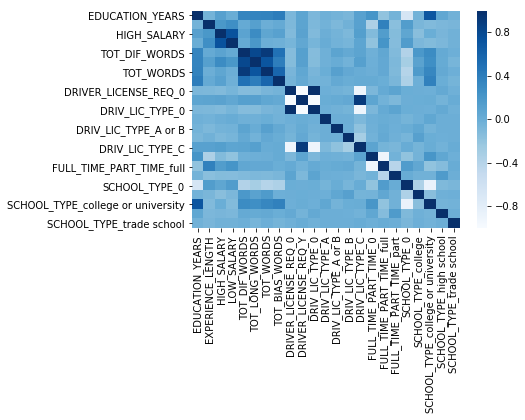

In [13]:
# Feature correlation
# Features are columns of data.  Feature correlation shows which columns affect each other.  
# A heatmap will highlight correlated data so we can investigate it 

print("\nFeatures (interesting data that can be analyzed): ")
cols = df2.columns
for col in cols:  print(col)

#plt.matshow(df2.corr())
#plt.show()

def seabornCM(corr):
    import seaborn as sns
    sns.heatmap(corr, cmap="Blues")

seabornCM(df2.corr())
plt.show()



QUESTIONS POSED FROM ANALYZING FEATURES


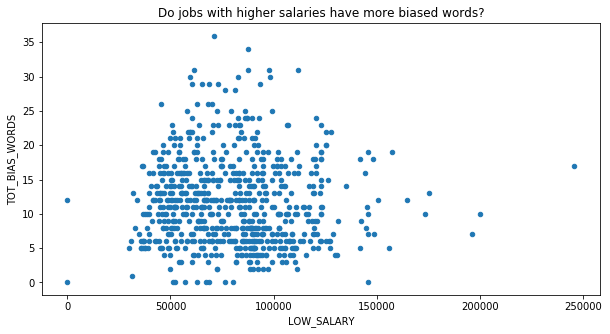


Do jobs with higher salaries have more biased words?
Yes, jobs with higher salaries tend to have more biased words.


In [14]:
print("\nQUESTIONS POSED FROM ANALYZING FEATURES")

df2.plot(figsize=(10,5), x="LOW_SALARY", y="TOT_BIAS_WORDS", kind="scatter", title="Do jobs with higher salaries have more biased words?")
plt.show()

print("\nDo jobs with higher salaries have more biased words?")
print("Yes, jobs with higher salaries tend to have more biased words.")


I'm a Public Relations Specialist, what is the next step in my career path?
PRINCIPAL PUBLIC RELATIONS REPRESENTATIVE


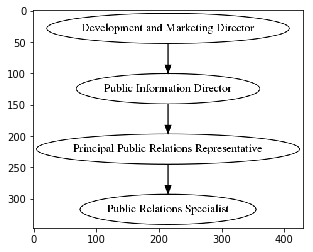

In [15]:
print("\nI'm a Public Relations Specialist, what is the next step in my career path?")
nextPromotions = jb['NEXT_PROMOTION'][jb['JOB_CLASS_TITLE'] == 'PUBLIC RELATIONS SPECIALIST']
for nextPromotion in nextPromotions: print(nextPromotion)
careerPathImg = "../input/jobbulletinresults/"+jb['DAG_FILE'][jb['JOB_CLASS_TITLE'] == 'PUBLIC RELATIONS SPECIALIST']

img = mpimg.imread(careerPathImg.item())
imgplot = plt.imshow(img)
plt.show()

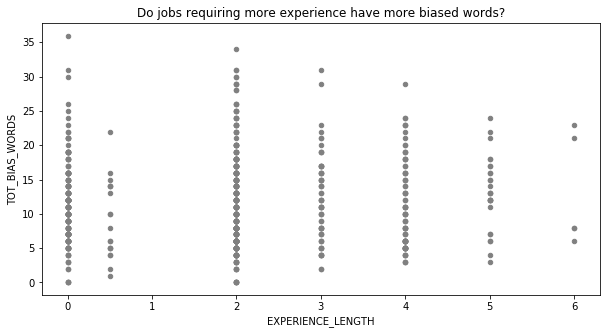


Do jobs requiring more experience have more biased words?
Inconclusive because jobs paying $100k to 150k tend to be more scientific so these Job Bulletins have more complex words.  I plan to investigate only the gender-based words as a future project


In [16]:
df2["EXPERIENCE_LENGTH"] = df2["EXPERIENCE_LENGTH"].fillna(0.0)
df2.plot(figsize=(10,5), x="EXPERIENCE_LENGTH", y="TOT_BIAS_WORDS", kind="scatter",  color="grey", title="Do jobs requiring more experience have more biased words?")
plt.show()

print("\nDo jobs requiring more experience have more biased words?")
print("Inconclusive because jobs paying $100k to 150k tend to be more scientific so these Job Bulletins have more complex words.  I plan to investigate only the gender-based words as a future project")


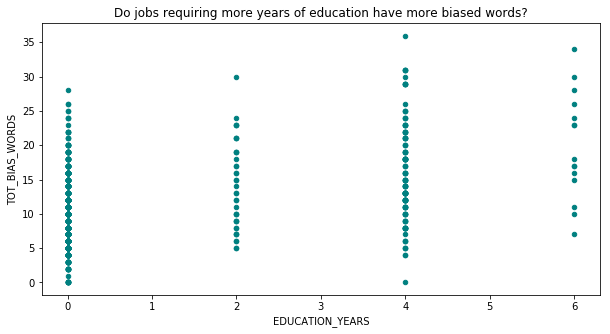


Do jobs requiring more years of education have more biased words?
Inconclusive for non-native speakers bias because Job Bulletins for jobs requiring more education often include words related to a specific field of study, such as oceanography...  If a professional is skilled in that field, they should know these words even if they are not a native speaker.


In [17]:
df2["EDUCATION_YEARS"] = df2["EDUCATION_YEARS"].fillna(0.0)
df2.plot(figsize=(10,5), x="EDUCATION_YEARS", y="TOT_BIAS_WORDS", kind="scatter",  color="teal", title="Do jobs requiring more years of education have more biased words?")
plt.show()

print("\nDo jobs requiring more years of education have more biased words?")
print("Inconclusive for non-native speakers bias because Job Bulletins for jobs requiring more education often include words related to a specific field of study, such as oceanography...  If a professional is skilled in that field, they should know these words even if they are not a native speaker.")

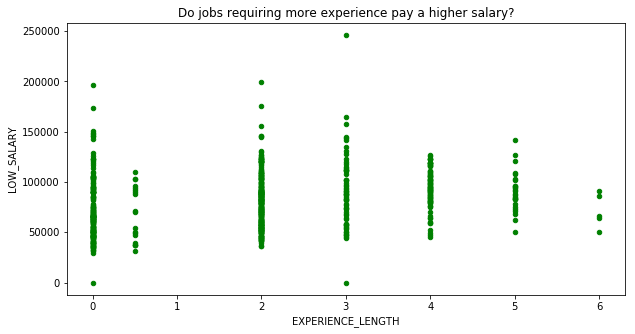


Do jobs requiring more experience pay a higher salary?
Inconclusive because EXPERIENCE_LENGTH needs to be double-checked.  It appears that some Job Bulletins only request the last 2-3 years of experience rather than a complete history while others ask for the history


In [18]:
df2["EXPERIENCE_LENGTH"] = df2["EXPERIENCE_LENGTH"].fillna(0.0)
df2.plot(figsize=(10,5), x="EXPERIENCE_LENGTH", y="LOW_SALARY", kind="scatter", color="green", title="Do jobs requiring more experience pay a higher salary?")
plt.show()

print("\nDo jobs requiring more experience pay a higher salary?")
print("Inconclusive because EXPERIENCE_LENGTH needs to be double-checked.  It appears that some Job Bulletins only request the last 2-3 years of experience rather than a complete history while others ask for the history")


In [19]:
word_in_file = dbw.groupby(['FILE_NAME'])['WORD'].count()
print("\nSTATISTICS FOR BIASED WORDS USED IN EACH JOB BULLETIN:")
print("\nMost biased words used in one Job Bulletin: ", word_in_file.max())
print("Least biased words used in one Job Bulletin: ", word_in_file.min())
print("Average biased words per Job Bulletin: ", int(round(word_in_file.mean(),0)))

print("\nThe number of times a biased word was used in each file:\n")
print(word_in_file.sort_values(ascending=False))
print("\nThe number of times each biased word was used in each file:")
print(dbw.groupby(['FILE_NAME','WORD'])['WORD'].count())



STATISTICS FOR BIASED WORDS USED IN EACH JOB BULLETIN:

Most biased words used in one Job Bulletin:  36
Least biased words used in one Job Bulletin:  1
Average biased words per Job Bulletin:  12

The number of times a biased word was used in each file:

FILE_NAME
JobBulletins/OPERATIONS AND STATISTICAL RESEARCH ANALYST 1779 110317.txt                    36
JobBulletins/FINANCIAL MANAGER 1557 070116 Rev.txt                                          34
JobBulletins/CHIEF INTERNAL AUDITOR 1619 090916 (5).txt                                     31
JobBulletins/CHEMIST  7833 102017.txt                                                       31
JobBulletins/DATABASE ARCHITECT 1470 083118.txt                                             31
JobBulletins/FINANCIAL DEVELOPMENT OFFICER 1571 102017 revised.txt                          31
JobBulletins/SENIOR CITY PLANNER 7947 051217.txt                                            30
JobBulletins/CRIME AND INTELLIGENCE ANALYST  2236  062918.txt         

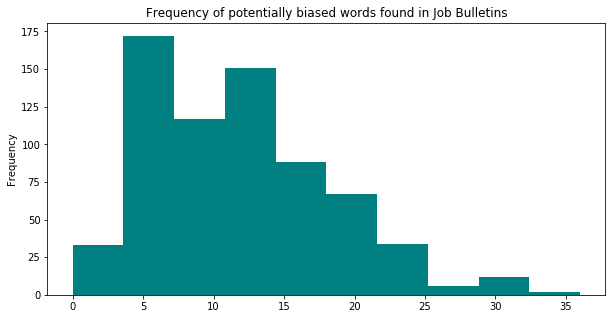

In [20]:
dstats['TOT_BIAS_WORDS'].plot(figsize=(10,5), kind='hist', color='teal', title='Frequency of potentially biased words found in Job Bulletins')
plt.show()   

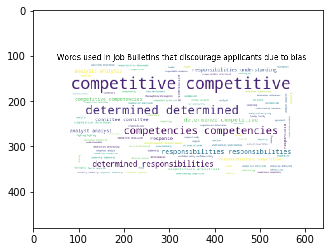

In [21]:
img = mpimg.imread("../input/jobbulletinresults/results.png")
imgplot = plt.imshow(img)
plt.show()

In [22]:
locateBias = dbias[['FILE_NAME','WORD_LOCATION','SENTENCE']]
locateBias = locateBias.drop_duplicates()
print("Number of times a biased word was found after dropping duplicates: ", len(locateBias))

Number of times a biased word was found after dropping duplicates:  5395


In [23]:
print("Job Bulletins containing 'open competitive candidates'")
res = locateBias[locateBias["SENTENCE"].str.contains("open competitive candidates", na=False)]
print(res)

# "Competition attracts male candidates.  Could a gender-neutral term be used instead?
# Perhaps "open-hire candidates" or "new-hire candidates"?  
# If "open competitive candidates" is the required term, then the City can place this word on the non-bias list
# and it will not appear in future analysis


Job Bulletins containing 'open competitive candidates'
                                              FILE_NAME WORD_LOCATION  \
14    JobBulletins/EQUIPMENT SPECIALIST 3734 111717 ...     9254-9265   
72    JobBulletins/ELECTRIC DISTRIBUTION MECHANIC 38...   16173-16184   
87    JobBulletins/WASTEWATER COLLECTION WORKER 4110...     7213-7224   
106   JobBulletins/PARKING METER TECHNICIAN 3738 110...     6147-6158   
120   JobBulletins/STREET SERVICES SUPERINTENDENT 41...     9648-9659   
146   JobBulletins/REINFORCING STEEL WORKER 3483 022...     5511-5522   
176       JobBulletins/SECRETARY LEGAL  1924 081718.txt     7070-7081   
217   JobBulletins/ENVIRONMENTAL COMPLIANCE INSPECTO...   14095-14106   
235   JobBulletins/LABORATORY TECHNICIAN 7854 030416...     7480-7491   
321   JobBulletins/STREET SERVICES WORKER 4150 03231...     8350-8361   
363   JobBulletins/INFORMATION SERVICES SPECIALIST 1...     5339-5350   
383   JobBulletins/CHIEF AIRPORTS ENGINEER 7274 0515...     8467-8478

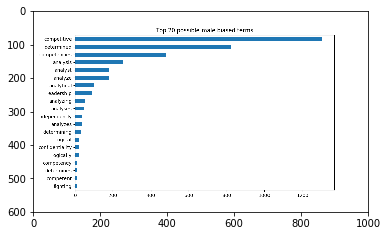

In [24]:
img = mpimg.imread("../input/jobbulletinresults/male2.png")
imgplot = plt.imshow(img)
plt.show()

In [25]:
print('Job Bulletins containing "COMPETITIVE BASIS"\n')
res = locateBias[locateBias["SENTENCE"].str.contains(">>> COMPETITIVE <<<  BASIS", na=False)]
print(res)

#Competitive basis" is a term that refers to the examination process.  Could a gender-neutral term be used such as "skills basis"
# If not, the City can add this term to the non-bias list 

Job Bulletins containing "COMPETITIVE BASIS"

                                              FILE_NAME WORD_LOCATION  \
17    JobBulletins/EQUIPMENT SPECIALIST 3734 111717 ...   10729-10740   
37    JobBulletins/ARCHITECTURAL ASSOCIATE 7926 0131...     8216-8227   
52     JobBulletins/TREASURY ACCOUNTANT 1609 102816.txt     9201-9212   
64    JobBulletins/VIDEO PRODUCTION COORDINATOR 1802...   11641-11652   
89    JobBulletins/WASTEWATER COLLECTION WORKER 4110...     8235-8246   
99    JobBulletins/STREET LIGHTING ENGINEERING ASSOC...     6986-6997   
109   JobBulletins/PARKING METER TECHNICIAN 3738 110...     7802-7813   
123   JobBulletins/STREET SERVICES SUPERINTENDENT 41...   10558-10569   
139       JobBulletins/GARAGE ATTENDANT 3531 013015.txt     7153-7164   
149   JobBulletins/REINFORCING STEEL WORKER 3483 022...     7188-7199   
166   JobBulletins/STEAM PLANT ASSISTANT 5622 051118...     9779-9790   
179       JobBulletins/SECRETARY LEGAL  1924 081718.txt     8718-8729   
220  

In [26]:
print('Job Bulletins containing "determines"\n')

res = locateBias[locateBias["SENTENCE"].str.contains("determines", na=False)]
print(res)

# "determines" attracts male candidates.  Could a gender-neutral word be used in these sentences?
# For example, "determines procedures and methods" could be replaced with "finds procedures and methods"


Job Bulletins containing "determines"

                                              FILE_NAME WORD_LOCATION  \
7     JobBulletins/EQUIPMENT SPECIALIST 3734 111717 ...       819-829   
1080    JobBulletins/PLUMBER SUPERVISOR 3446 100518.txt       924-934   
1310  JobBulletins/APPLICATIONS PROGRAMMER 1429 0629...       853-863   
1322  JobBulletins/APPLICATIONS PROGRAMMER 1429 0629...       792-801   
2143  JobBulletins/WATER SERVICE REPRESENTATIVE 1693...       960-970   
2145  JobBulletins/WATER SERVICE REPRESENTATIVE 1693...       906-916   
2891     JobBulletins/TIRE REPAIRER 3727 091517 (1).txt       719-729   
4373  JobBulletins/SIGNAL SYSTEMS SUPERINTENDENT 383...       619-629   
5296  JobBulletins/SENIOR COMMERCIAL FIELD REPRESENT...       935-945   
6076  JobBulletins/PROGRAMMER ANALYST 1431 092217 (3...     1034-1044   
6100  JobBulletins/PROGRAMMER ANALYST 1431 092217 (3...      992-1000   
6242           JobBulletins/ZOO CURATOR 4297 040816.txt       449-459   
6243        

In [27]:
print('Job Bulletins containing "competencies"\n')
res = locateBias[locateBias["SENTENCE"].str.contains("competencies", na=False)]
print(res)

# "competencies" is a complex word rarely used in daily speech.
# "competencies" could be replaced with "skills" because "skills" is a more commonly used word


Job Bulletins containing "competencies"

                                              FILE_NAME WORD_LOCATION  \
23    JobBulletins/EQUIPMENT SPECIALIST 3734 111717 ...     5988-6000   
128   JobBulletins/STREET SERVICES SUPERINTENDENT 41...     7288-7300   
184       JobBulletins/SECRETARY LEGAL  1924 081718.txt     4175-4187   
273           JobBulletins/PHOTOGRAPHER 1793 041516.txt     3676-3688   
274           JobBulletins/PHOTOGRAPHER 1793 041516.txt     6134-6146   
338   JobBulletins/AIRPORT SUPERINTENDENT OF OPERATI...     5112-5124   
339   JobBulletins/AIRPORT SUPERINTENDENT OF OPERATI...     6014-6026   
340   JobBulletins/AIRPORT SUPERINTENDENT OF OPERATI...     6944-6956   
372   JobBulletins/INFORMATION SERVICES SPECIALIST 1...     3164-3176   
406   JobBulletins/PLANNING ASSISTANT 7939 071417 RE...     7387-7399   
429   JobBulletins/SENIOR ADMINISTRATIVE CLERK 1368 ...     3766-3778   
431   JobBulletins/SENIOR ADMINISTRATIVE CLERK 1368 ...     7668-7680   
502   JobB

In [28]:
print("Other words were found that are biased towards women and non-native speakers")

Other words were found that are biased towards women and non-native speakers


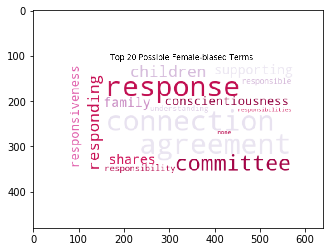

Job Bulletins containing the most used word biased towards women:  "responsibilities"

                                              FILE_NAME WORD_LOCATION  \
2     JobBulletins/PARKING ENFORCEMENT MANAGER 9025 ...      993-1009   
6     JobBulletins/EQUIPMENT SPECIALIST 3734 111717 ...     7565-7581   
34    JobBulletins/STREET SERVICES SUPERVISOR 4152 0...     1206-1222   
119   JobBulletins/STREET SERVICES SUPERINTENDENT 41...       870-886   
158   JobBulletins/SENIOR UNDERGROUND DISTRIBUTION C...     1073-1089   
159   JobBulletins/SENIOR UNDERGROUND DISTRIBUTION C...     6032-6048   
175       JobBulletins/SECRETARY LEGAL  1924 081718.txt     1183-1199   
193   JobBulletins/SENIOR SAFETY ENGINEER PRESSURE V...     1099-1115   
194   JobBulletins/SENIOR SAFETY ENGINEER PRESSURE V...     4988-5004   
201   JobBulletins/PRINCIPAL MECHANICAL ENGINEERING ...     1190-1206   
206   JobBulletins/DISTRICT SUPERVISOR ANIMAL SERVIC...     1713-1729   
207   JobBulletins/DISTRICT SUPERVISO

In [29]:
img = mpimg.imread('../input/jobbulletinresults/female.png')
imgplot = plt.imshow(img)
plt.show()

print('Job Bulletins containing the most used word biased towards women:  "responsibilities"\n')
res = locateBias[locateBias["SENTENCE"].str.contains("responsibilities", na=False)]
print(res)

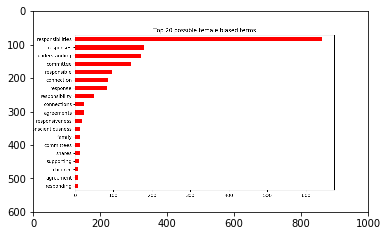

In [30]:
img = mpimg.imread('../input/jobbulletinresults/female2.png')
imgplot = plt.imshow(img)
plt.show()

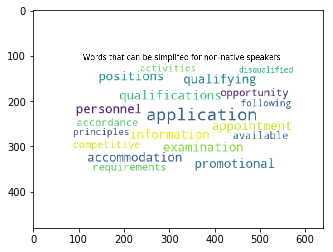

In [31]:
img = mpimg.imread('../input/jobbulletinresults/nonnative.png')
imgplot = plt.imshow(img)
plt.show()

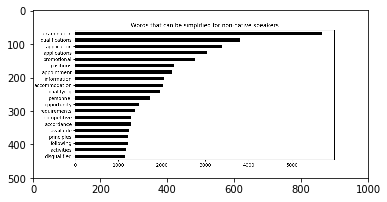

Job Bulletins containing the most used word biased towards non-native speakers: "examination"

                                              FILE_NAME WORD_LOCATION  \
39    JobBulletins/ARCHITECTURAL ASSOCIATE 7926 0131...     3151-3158   
44     JobBulletins/ENGINEER OF SURVEYS 9486 101615.txt     4549-4558   
129   JobBulletins/STREET SERVICES SUPERINTENDENT 41...     8240-8252   
275           JobBulletins/PHOTOGRAPHER 1793 041516.txt     7758-7770   
395   JobBulletins/PLANNING ASSISTANT 7939 071417 RE...     8365-8375   
545   JobBulletins/ENGINEERING GEOLOGIST ASSOCIATE 7...     5719-5728   
730           JobBulletins/FIRE CAPTAIN 2142 033018.txt     8990-9001   
752   JobBulletins/COMMUNITY AFFAIRS ADVOCATE  11141...     3795-3804   
805   JobBulletins/SUPERVISING OCCUPATIONAL HEALTH  ...     4504-4513   
948   JobBulletins/CRIME AND INTELLIGENCE ANALYST  2...     7544-7551   
960   JobBulletins/CRIME AND INTELLIGENCE ANALYST  2...     7502-7514   
1133  JobBulletins/APPARATUS 

In [32]:
img = mpimg.imread('../input/jobbulletinresults/nonnative-2.png')
imgplot = plt.imshow(img)
plt.show()

print('Job Bulletins containing the most used word biased towards non-native speakers: "examination"\n')
res = locateBias[locateBias["SENTENCE"].str.contains("examination", na=False)]
print(res)

# Can "examination" be replaced with "exam" or "test"?